# The Gilded Ace — final product evidence
**Final dashboard revision:** `2a124ca0b901ab9e4c18d87f471679c0673600a1`. All casino and guest data is synthetic. Historical evidence: January–June 2025. Modeled horizon: July 1–30, 2025.

This notebook uses the exact archived source/data snapshot of the final dashboard, including the shared forecast and floor-simulation modules. It reruns checks and presents the main evidence and planning results in Databricks. The interactive Streamlit/SVG application remains a separately launched local application; this is not a hosted floor app.

Read the final section of this notebook for version boundaries, assumptions, source documentation and the Devpost description. The original notebook's property forecast and version-1 simulation are retained as historical evidence, not substituted for this model.
**Verified in Databricks:** [successful run](https://dbc-3501c3c5-1cc4.cloud.databricks.com/?o=7474651870217400#job/796646835901211/run/1115290540544965). Saved outputs below are copied from that cloud run.


In [1]:
from pathlib import Path
import sys, json, hashlib, tempfile, zipfile, io, unittest, runpy
import numpy as np
import pandas as pd
VOLUME = Path('/Volumes/workspace/default/dashboard_royale_source/final_product/2a124ca')
ARCHIVE = VOLUME / 'aceiq_final_product.zip'
EXPECTED_SHA256 = 'f8b6e0d01983c1e6a249a0cc2d4c03e9f1a8ca3e3afe0a41de14d101d7d72e99'
assert hashlib.sha256(ARCHIVE.read_bytes()).hexdigest() == EXPECTED_SHA256, 'Source archive mismatch'
FINAL_ROOT = Path(tempfile.mkdtemp(prefix='aceiq-final-'))
with zipfile.ZipFile(ARCHIVE) as archive:
    for member in archive.infolist():
        target=(FINAL_ROOT/member.filename).resolve()
        assert target.is_relative_to(FINAL_ROOT.resolve()), 'Unsafe archive path'
    archive.extractall(FINAL_ROOT)
source_manifest=json.loads((FINAL_ROOT/'SOURCE_MANIFEST.json').read_text())
for filename,expected_hash in source_manifest['files'].items():
    assert hashlib.sha256((FINAL_ROOT/filename).read_bytes()).hexdigest()==expected_hash, filename
sys.path.insert(0,str(FINAL_ROOT))
# Remove any earlier imported project version from this Python session.
for module_name in list(sys.modules):
    if module_name=='dashboard' or module_name.startswith('dashboard.'):
        del sys.modules[module_name]
from dashboard.data_bundle import load_bundle
from dashboard.analytics import machine_summary
from dashboard.forecast import build_forecasts, aggregate_predictions
from dashboard.decisions import rank_portfolios
from dashboard.floor_simulation import FloorSimulation
final_bundle=load_bundle()
fd=final_bundle['daily']; fm=final_bundle['machines']; fp=final_bundle['property']
fr=final_bundle['report']; fg=final_bundle['guests']; predictions=final_bundle['predictions']
summary=machine_summary(fd,fm)
VERIFY=VOLUME/'verification'
VERIFY.mkdir(exist_ok=True)
print('Verified source commit:',source_manifest['git_commit'])
print('SHA-256 checked files:',len(source_manifest['files']))
print('Only versioned verification outputs are written; source tables and historical exports are unchanged.')

Verified source commit: 2a124ca0b901ab9e4c18d87f471679c0673600a1
SHA-256 checked files: 76
Only versioned verification outputs are written; source tables and historical exports are unchanged.


## 1. Reconcile the final product with the cloud table
The snapshot contains 55,092 active machine-days; the original prepared table also contains inactive rows. Comparisons below use active rows consistently. Earnings are before operating costs. Player net is payouts minus wagers.

In [2]:
cloud = spark.sql("""SELECT count(*) AS active_rows,
    sum(coin_in_usd) AS wagers, sum(payout_usd) AS payouts,
    sum(house_win_usd) AS actual, sum(theo_usd) AS expected
    FROM workspace.default.prepared_daily_view WHERE active = true""").first().asDict()
local={'active_rows':len(fd),'wagers':float(fd.coin_in_usd.sum()),
       'payouts':float((fd.coin_in_usd-fd.house_win_usd).sum()),
       'actual':float(fd.house_win_usd.sum()),'expected':float(fd.theo_usd.sum())}
for key,value in local.items():
    np.testing.assert_allclose(float(cloud[key]),value,rtol=0,atol=.01)
display(pd.DataFrame([{'Measure':k,'Cloud active rows':float(cloud[k]),'Final local exports':v} for k,v in local.items()]))
print('PASS: final dashboard exports reconcile with the Databricks prepared table.')

Measure,Cloud active rows,Final local exports
active_rows,5.509200e+04,5.509200e+04
wagers,2.489052e+08,2.489052e+08
payouts,2.252671e+08,2.252671e+08
actual,2.363816e+07,2.363816e+07
expected,2.354536e+07,2.354536e+07


PASS: final dashboard exports reconcile with the Databricks prepared table.


## 2. Focused regression checks
These are the same financial, source-reference, leakage, placement and floor-engine checks used locally. Browser/UI and localhost HTTP tests remain local; they are not claimed as Databricks tests.

In [3]:
test_log=io.StringIO()
suite=unittest.TestSuite()
loader=unittest.TestLoader()
for name in ['test_results.py','test_reference_consistency.py','test_floor_simulation.py']:
    suite.addTests(loader.discover(str(FINAL_ROOT/'tests'),pattern=name))
test_result=unittest.TextTestRunner(stream=test_log,verbosity=1).run(suite)
print(test_log.getvalue())
assert test_result.wasSuccessful(), 'Regression check failed'
runpy.run_path(str(FINAL_ROOT/'tests/test_upgrade.py'))
print('PASS: independent money/variance/forecast reconciliation, floor validation, atomic swaps, suggestions and leakage checks.')

................
----------------------------------------------------------------------
Ran 16 tests in 2.614s

OK

PASS: period-specific variance, July occupancy, no holdout-target leakage, shared action math, catalog scope and budget.
July occupied / empty: 308 6
Candidate plans: 42
PASS: independent money/variance/forecast reconciliation, floor validation, atomic swaps, suggestions and leakage checks.


## 3. Chart conventions
Charts below use the final data definitions. They are static evidence charts in a notebook, not copies of the browser controls. The original pixel font is used for headings; axes remain readable monospace. Downloaded chart PNGs are written only to this revision's verification folder.

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager, ticker
font_manager.fontManager.addfont(str(FINAL_ROOT/'assets/fonts/Silkscreen-Regular.ttf'))
plt.rcParams.update({'figure.facecolor':'#0b231f','axes.facecolor':'#0b231f',
    'text.color':'#f6eacb','axes.labelcolor':'#f6eacb','xtick.color':'#f6eacb','ytick.color':'#f6eacb',
    'axes.edgecolor':'#426457','font.family':'monospace','font.size':11,'figure.dpi':120,
    'axes.spines.top':False,'axes.spines.right':False})
GOLD='#e4bd75';TEAL='#75c9b9';ROSE='#d2919e'
chart_files=[]
def figure(title,size=(12,4.8)):
    fig,ax=plt.subplots(figsize=size)
    ax.set_title(title,fontfamily='Silkscreen',fontsize=13,pad=20)
    ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
    return fig,ax
def finish(fig,name):
    fig.tight_layout()
    buffer=io.BytesIO();fig.savefig(buffer,format='png',bbox_inches='tight')
    (VERIFY/name).write_bytes(buffer.getvalue());chart_files.append(name)
    display(fig);plt.close(fig)
def dollars(ax,axis='y'):
    formatter=ticker.FuncFormatter(lambda v,p: f'${v/1e6:.1f}m' if abs(v)>=1e6 else f'${v/1000:.0f}k' if abs(v)>=1000 else f'${v:.0f}')
    (ax.yaxis if axis=='y' else ax.xaxis).set_major_formatter(formatter)

## 4. Which machines deserve investigation?
Raw low earnings mix exposure, availability, demand and payout variation. The index is actual house win divided by expected earnings; 100% means actual equals expected. Negative values are kept. Change `rank_by` below to mirror the dashboard's three ranking choices.

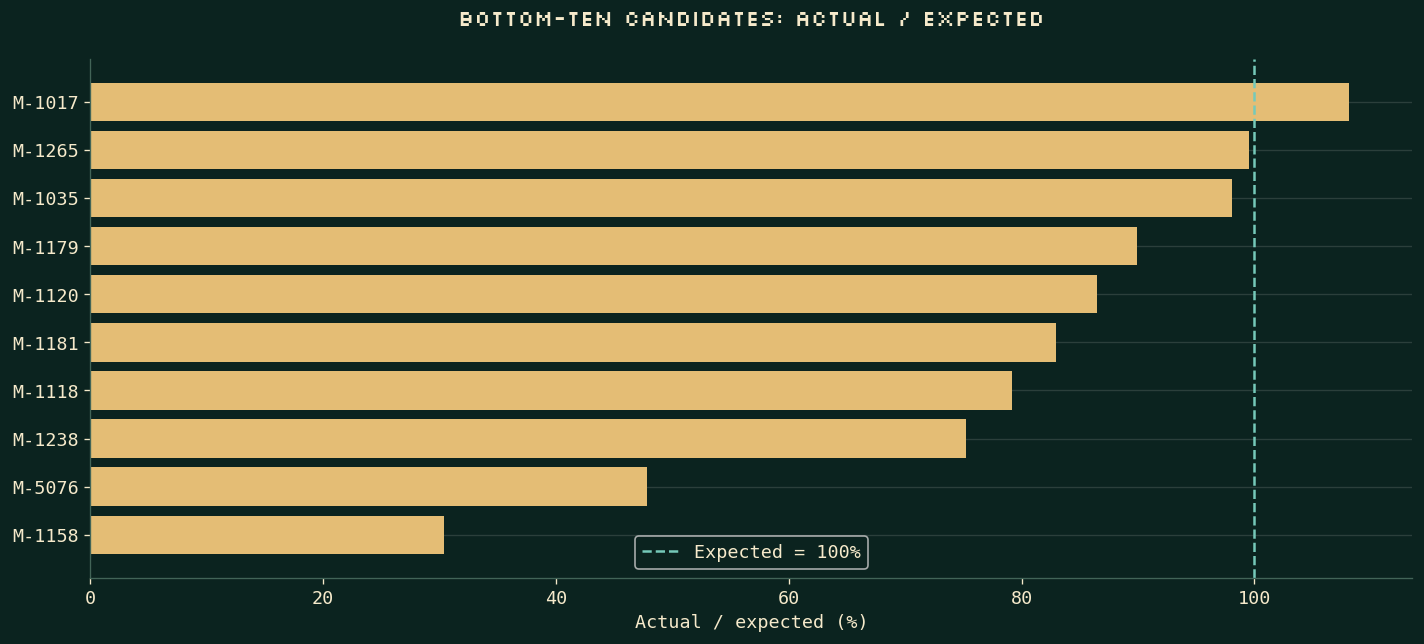

machine_id,actual_house_win,expected_house_win,active_days,availability_rate,standardized_gap
M-1158,15796.25,51961.0000,181,0.999306,-4.570146
M-5076,3573.25,7478.7000,49,0.994898,-1.853320
M-1238,24932.75,33139.3125,181,0.997422,-1.815428
M-1118,20050.00,25329.0000,55,0.995048,-0.648789
M-1181,26977.00,32516.1600,181,0.997840,-2.405914
M-1120,16355.00,18910.9250,132,0.994684,-0.788028
M-1179,30393.75,33784.7000,181,0.995908,-1.455003
M-1035,30303.50,30894.6000,181,0.999168,-0.136155
M-1265,32071.00,32208.8800,181,0.998146,-0.060152
M-1017,31939.50,29525.6375,181,0.997608,0.578162


Takeaway: M-1158 realized 30.4% of expected earnings over 181 active days. This is a screen, not a defect diagnosis.


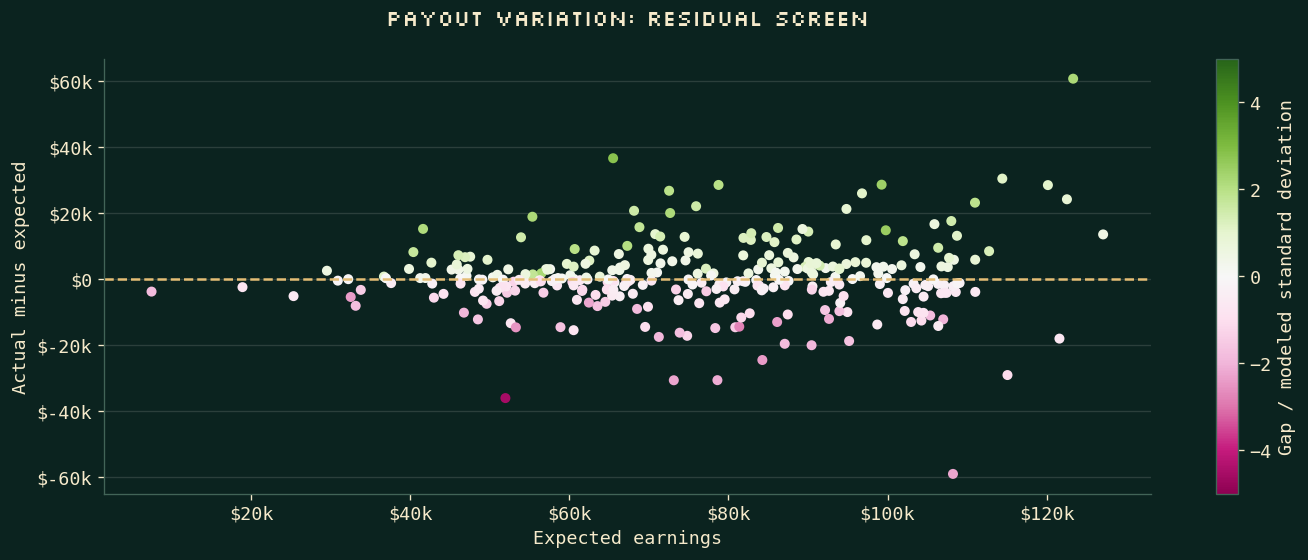

Guardrail: modeled payout variance and multiple-machine screening matter. This is not a multiple-testing-adjusted significance test.


In [5]:
rank_by='actual_house_win' # alternatives: actual_per_active_day, expected_per_available_hour
bottom=summary.sort_values([rank_by,'machine_id']).head(10).copy()
bottom['actual_index']=100*bottom.actual_house_win/bottom.expected_house_win.replace(0,np.nan)
bottom=bottom.sort_values('actual_index')
fig,ax=figure('Bottom-ten candidates: actual / expected',size=(12,5.5))
ax.barh(bottom.machine_id,bottom.actual_index,color=GOLD);ax.axvline(100,color=TEAL,ls='--',label='Expected = 100%')
ax.set_xlabel('Actual / expected (%)');ax.legend();finish(fig,'01_bottom_ten.png')
display(bottom[['machine_id','actual_house_win','expected_house_win','active_days','availability_rate','standardized_gap']])
weak=bottom.iloc[0]
print(f'Takeaway: {weak.machine_id} realized {weak.actual_index:.1f}% of expected earnings over {int(weak.active_days)} active days. This is a screen, not a defect diagnosis.')
fig,ax=figure('Payout variation: residual screen')
points=ax.scatter(summary.expected_house_win,summary.actual_minus_expected,c=summary.standardized_gap,cmap='PiYG',vmin=-5,vmax=5,s=25)
fig.colorbar(points,ax=ax,label='Gap / modeled standard deviation');ax.axhline(0,color=GOLD,ls='--')
ax.set_xlabel('Expected earnings');ax.set_ylabel('Actual minus expected');dollars(ax);dollars(ax,'x');finish(fig,'02_residuals.png')
print('Guardrail: modeled payout variance and multiple-machine screening matter. This is not a multiple-testing-adjusted significance test.')

## 5. Machine investigation and monthly availability
Select a machine below. Variance is summed for the selected evidence period, avoiding reuse of an unrelated full-period payout score. Monthly downtime is measured in hours, not a percentage.

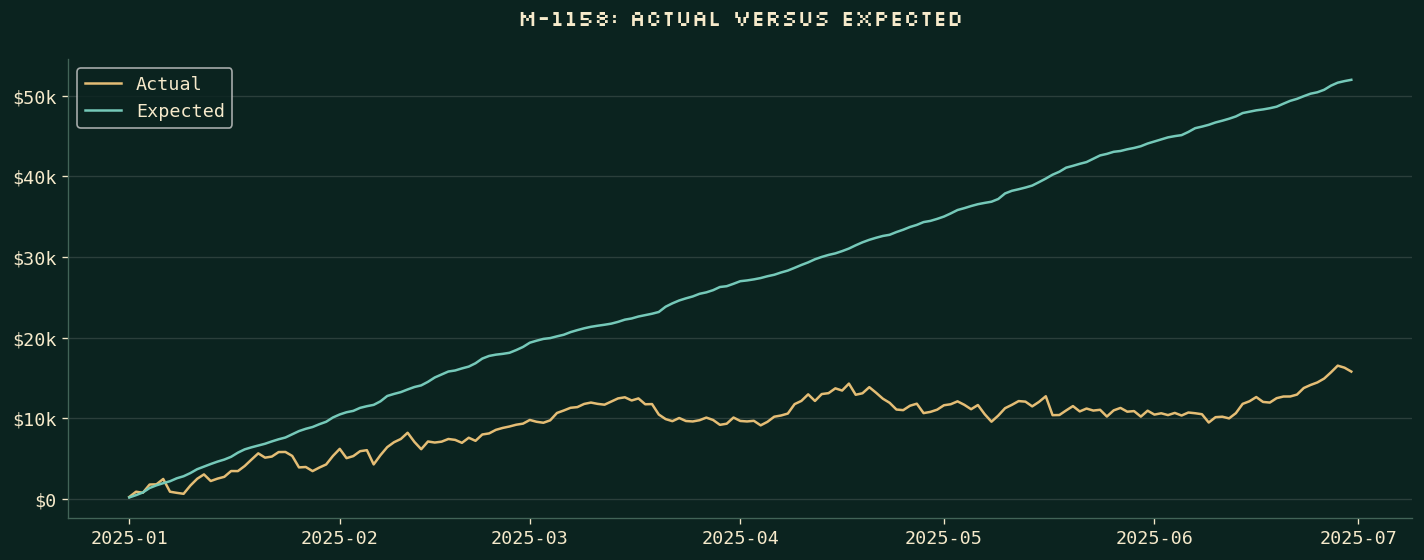

Takeaway: gap $-36,164.75; modeled residual -4.57 SD; availability 99.93%. Check configuration/meters before irreversible action.


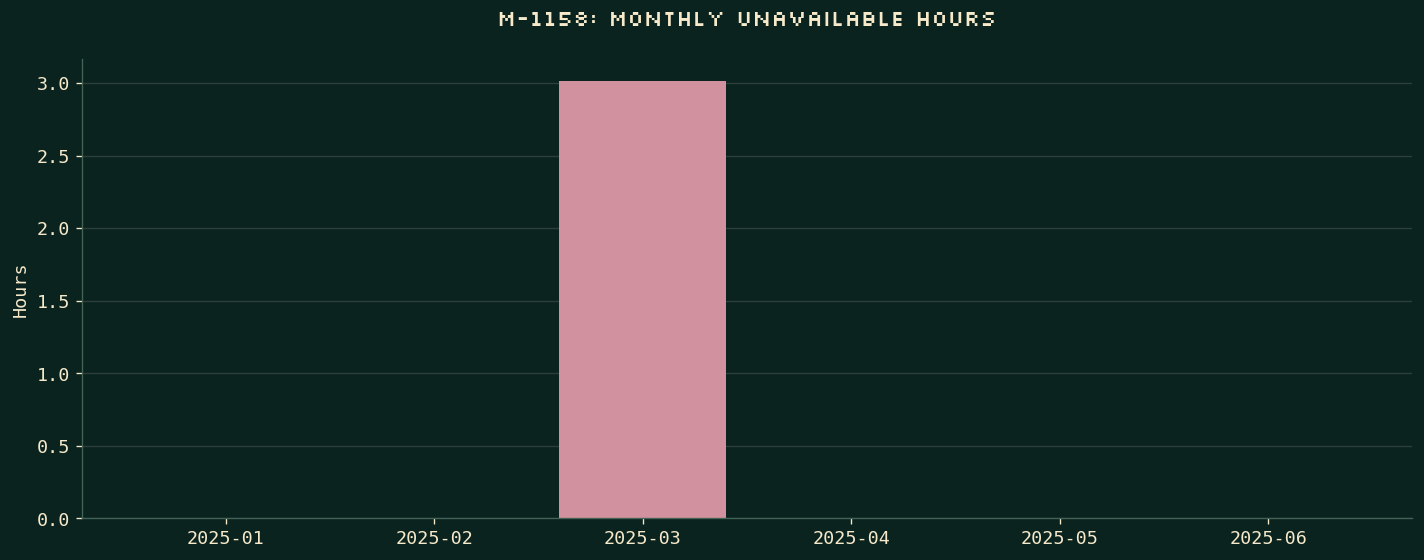

month,down,available,scheduled,availability
2025-01,0.000000,744.000000,744.0,1.000000
2025-02,0.000000,672.000000,672.0,1.000000
2025-03,3.014722,739.985278,743.0,0.995943
2025-04,0.000000,720.000000,720.0,1.000000
2025-05,0.000000,744.000000,744.0,1.000000
2025-06,0.000000,720.000000,720.0,1.000000


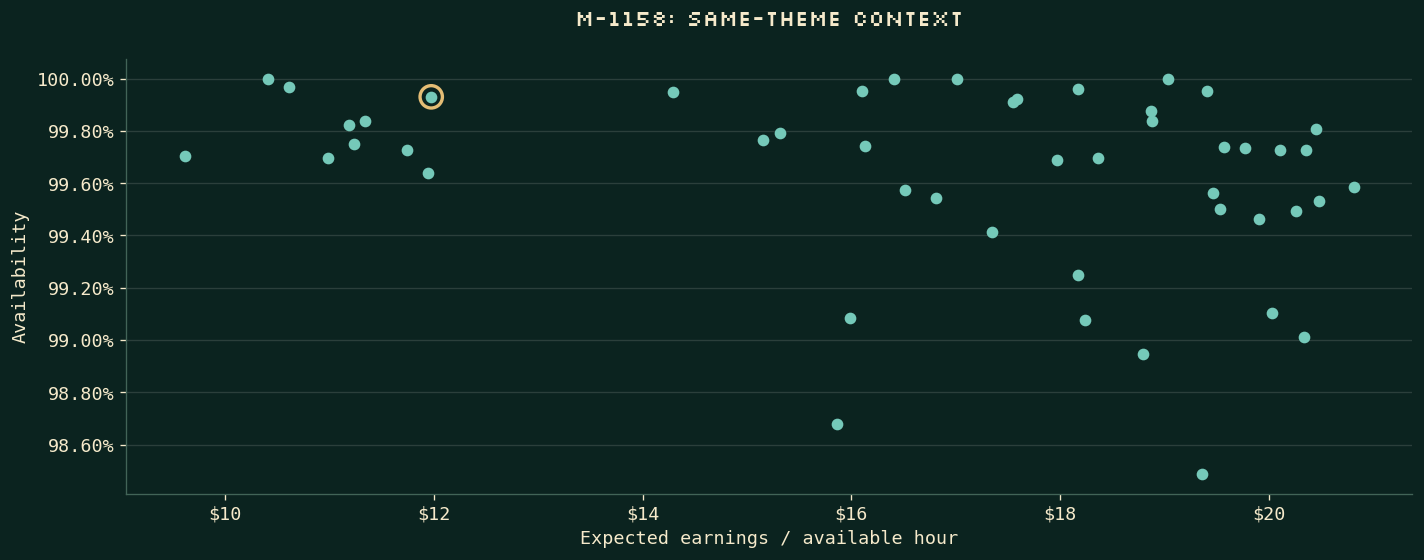

placement_id,machine_id,location_id,config_id,effective_from_utc,effective_to_utc
PL075de0cebb918145,M-1158,L-31-4,G-STD90,2025-01-01T14:00:00.000Z,None


Peers and placement histories are descriptive: they do not fully control denomination, guest mix or location effects.


In [6]:
machine_id='M-1158'
evidence_start=pd.Timestamp('2025-01-01'); evidence_end=pd.Timestamp('2025-06-30')
chosen=fd[(fd.machine_id==machine_id)&fd.gaming_date.between(evidence_start,evidence_end)].sort_values('gaming_date')
row=machine_summary(chosen,fm).iloc[0]
fig,ax=figure(machine_id+': actual versus expected')
ax.plot(chosen.gaming_date,chosen.house_win_usd.cumsum(),color=GOLD,label='Actual')
ax.plot(chosen.gaming_date,chosen.theo_usd.cumsum(),color=TEAL,label='Expected');ax.legend();dollars(ax);finish(fig,'03_machine_cumulative.png')
print(f'Takeaway: gap ${row.actual_minus_expected:,.2f}; modeled residual {row.standardized_gap:.2f} SD; availability {row.availability_rate:.2%}. Check configuration/meters before irreversible action.')
monthly=chosen.groupby('month',as_index=False).agg(down=('down_hours','sum'),available=('available_hours','sum'),scheduled=('scheduled_hours','sum'))
monthly['availability']=monthly.available/monthly.scheduled
fig,ax=figure(machine_id+': monthly unavailable hours');ax.bar(monthly.month,monthly.down,color=ROSE);ax.set_ylabel('Hours');finish(fig,'04_monthly_downtime.png');display(monthly)
peers=summary[summary.theme==row.theme]
fig,ax=figure(machine_id+': same-theme context');ax.scatter(peers.expected_per_available_hour,peers.availability_rate,color=TEAL)
ax.scatter([row.expected_per_available_hour],[row.availability_rate],s=180,facecolors='none',edgecolors=GOLD,linewidths=2)
ax.set_xlabel('Expected earnings / available hour');ax.set_ylabel('Availability');ax.yaxis.set_major_formatter(ticker.PercentFormatter(1));dollars(ax,'x');finish(fig,'05_theme_peers.png')
display(final_bundle['placements'][final_bundle['placements'].machine_id==machine_id])
print('Peers and placement histories are descriptive: they do not fully control denomination, guest mix or location effects.')

## 6. Demand, events, traffic and downtime opportunity
Normalize demand by available machine-hours to distinguish play intensity from month length and exposure. Event comparisons and traffic summaries are fixed January–June context. Missing counter coverage is not zero traffic.

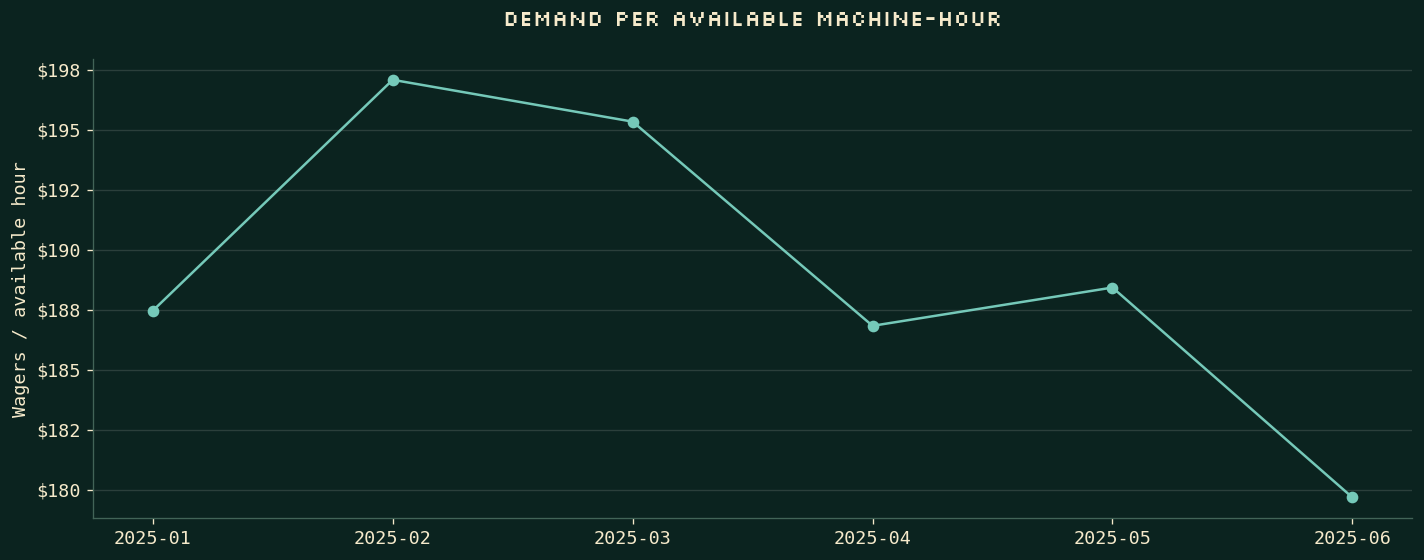

Takeaway: demand peaked in 2025-02 at $197.07/hour; 2025-06 was $179.67/hour, -8.8% from peak.


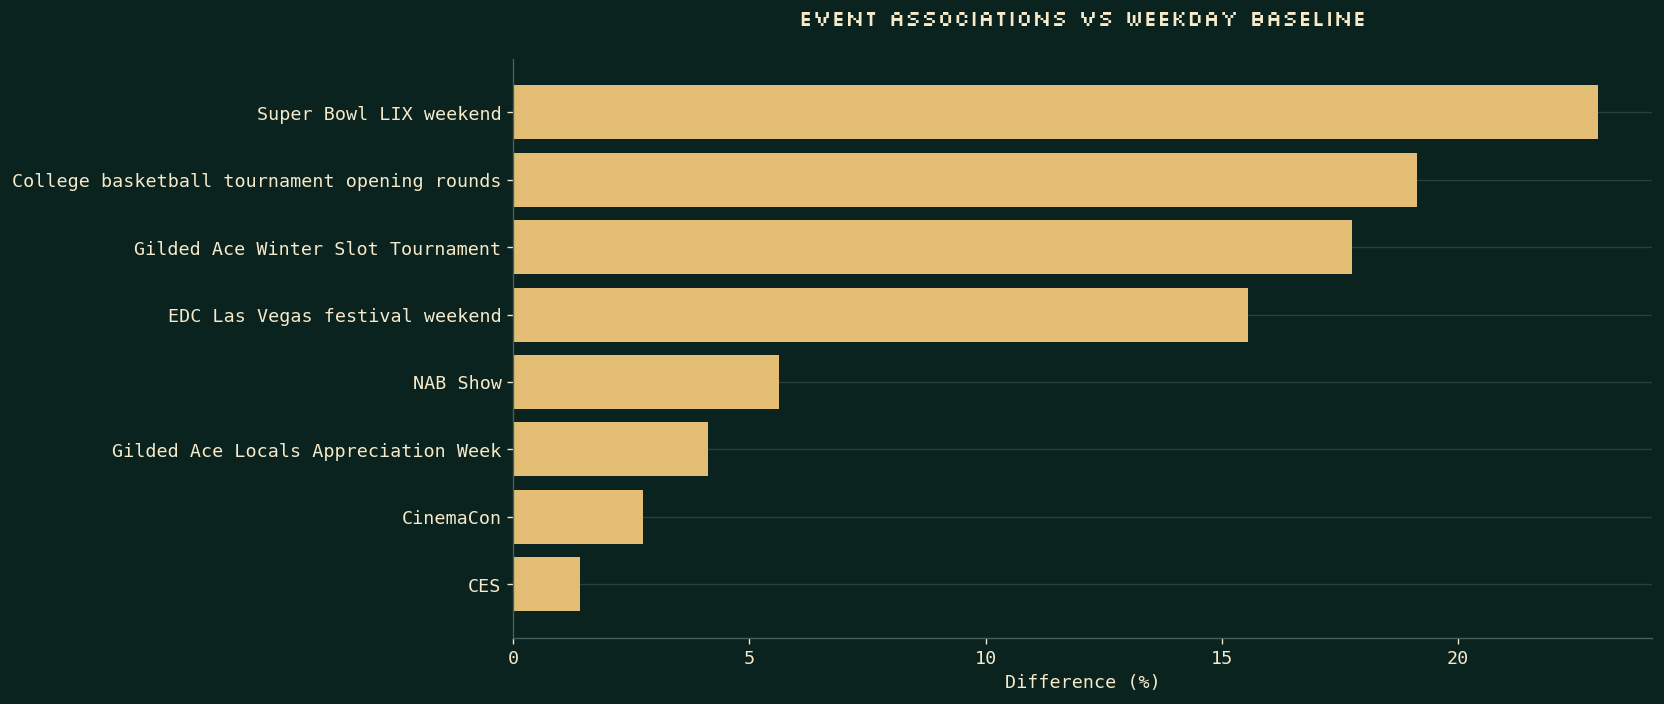

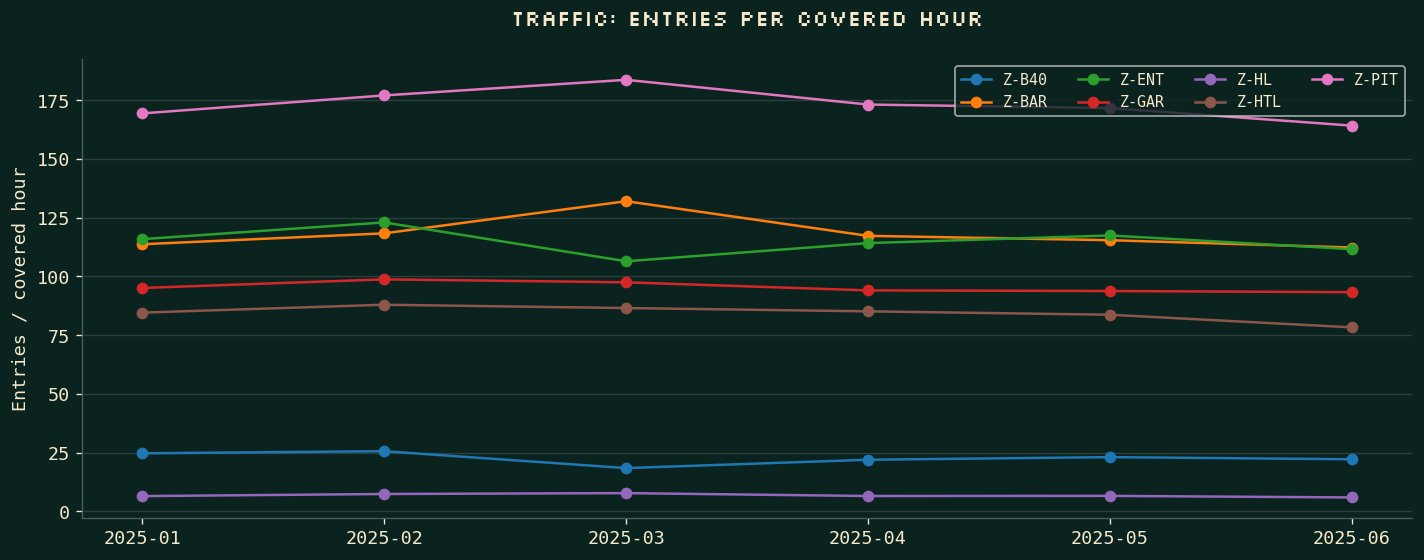

Counter entries are not unique people. Minimum valid interval share: 96.0%. Events are associations, not causal estimates.


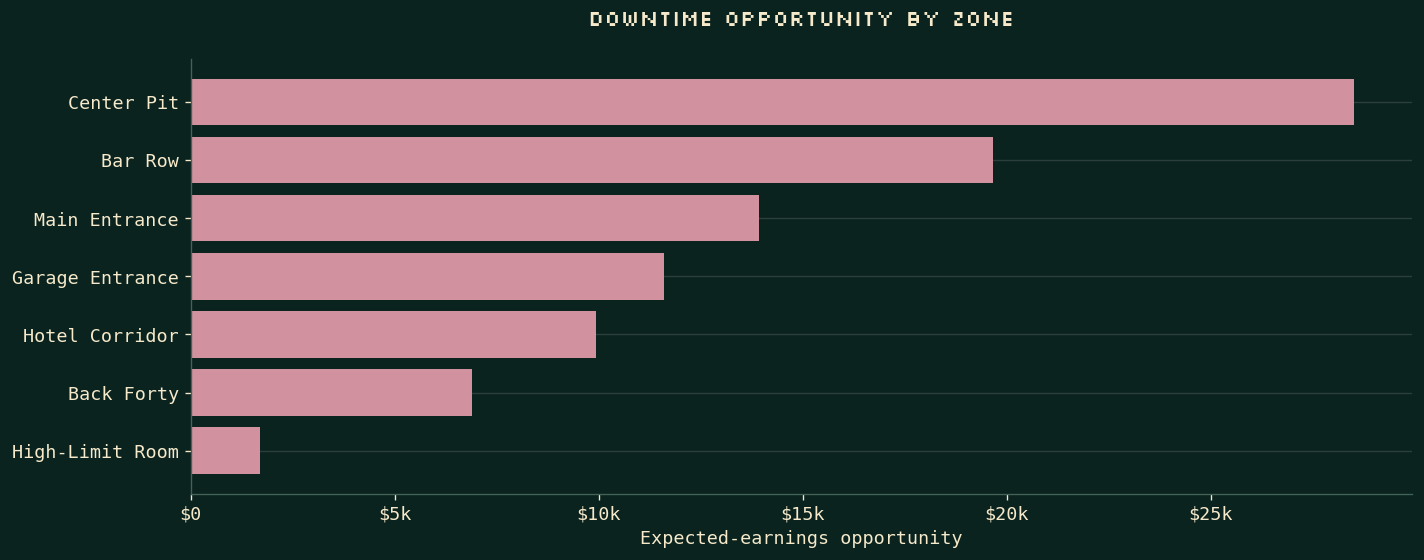

Takeaway: 5,021.1 unavailable hours and $92,253.68 estimated expected-earnings opportunity. Displaced play may be retained elsewhere; this is not proven net floor loss.


In [7]:
months=fd.groupby('month',as_index=False).agg(wagers=('coin_in_usd','sum'),hours=('available_hours','sum'))
months['wagers_per_hour']=months.wagers/months.hours
fig,ax=figure('Demand per available machine-hour');ax.plot(months.month,months.wagers_per_hour,'o-',color=TEAL);dollars(ax);ax.set_ylabel('Wagers / available hour');finish(fig,'06_demand_rate.png')
peak=months.loc[months.wagers_per_hour.idxmax()];last=months.iloc[-1]
print(f'Takeaway: demand peaked in {peak.month} at ${peak.wagers_per_hour:.2f}/hour; {last.month} was ${last.wagers_per_hour:.2f}/hour, {(last.wagers_per_hour/peak.wagers_per_hour-1):.1%} from peak.')
events=pd.DataFrame(fr['event_associations']).sort_values('difference_pct')
fig,ax=figure('Event associations vs weekday baseline',size=(14,6));ax.barh(events.event,events.difference_pct*100,color=GOLD);ax.set_xlabel('Difference (%)');finish(fig,'07_event_context.png')
traffic=pd.DataFrame(fr['traffic'])
fig,ax=figure('Traffic: entries per covered hour')
for zone,group in traffic.groupby('zone_id'):ax.plot(group.month,group.entries_per_covered_hour,'o-',label=zone)
ax.legend(ncol=4,fontsize=9);ax.set_ylabel('Entries / covered hour');finish(fig,'08_traffic.png')
print(f'Counter entries are not unique people. Minimum valid interval share: {traffic.valid_interval_share.min():.1%}. Events are associations, not causal estimates.')
zone_loss=fd.groupby('zone_name',as_index=False).agg(opportunity=('missed_theo_mid','sum'),hours=('down_hours','sum')).sort_values('opportunity')
fig,ax=figure('Downtime opportunity by zone');ax.barh(zone_loss.zone_name,zone_loss.opportunity,color=ROSE);dollars(ax,'x');ax.set_xlabel('Expected-earnings opportunity');finish(fig,'09_downtime_zone.png')
print(f'Takeaway: {fd.down_hours.sum():,.1f} unavailable hours and ${fd.missed_theo_mid.sum():,.2f} estimated expected-earnings opportunity. Displaced play may be retained elsewhere; this is not proven net floor loss.')

## 7. Tracked guests and loyalty economics
Grouped guest exports contain player-months, not distinct guest counts. Six-month concentration is a separately computed fixed-cohort statistic. Guest net is payouts minus wagers. Economic comp cost differs from face value and is included in linked POS COGS: do not subtract both twice.

period_month,wagers,payouts,player_net,expected,comp_cost,player_months
2025-01,27260837.20,24663556.40,-2597280.80,2580580.7505,28750.3,24687
2025-02,26143705.40,23557908.45,-2585796.95,2480599.8060,29854.3,24031
2025-03,28892699.50,26159442.15,-2733257.35,2733322.9005,33255.5,26346
2025-04,26775173.15,24292634.15,-2482539.00,2528175.5610,31390.3,24555
2025-05,28179263.55,25535976.25,-2643287.30,2658428.7580,34446.1,25970
2025-06,26553190.85,24009891.65,-2543299.20,2503913.2045,32972.8,23304


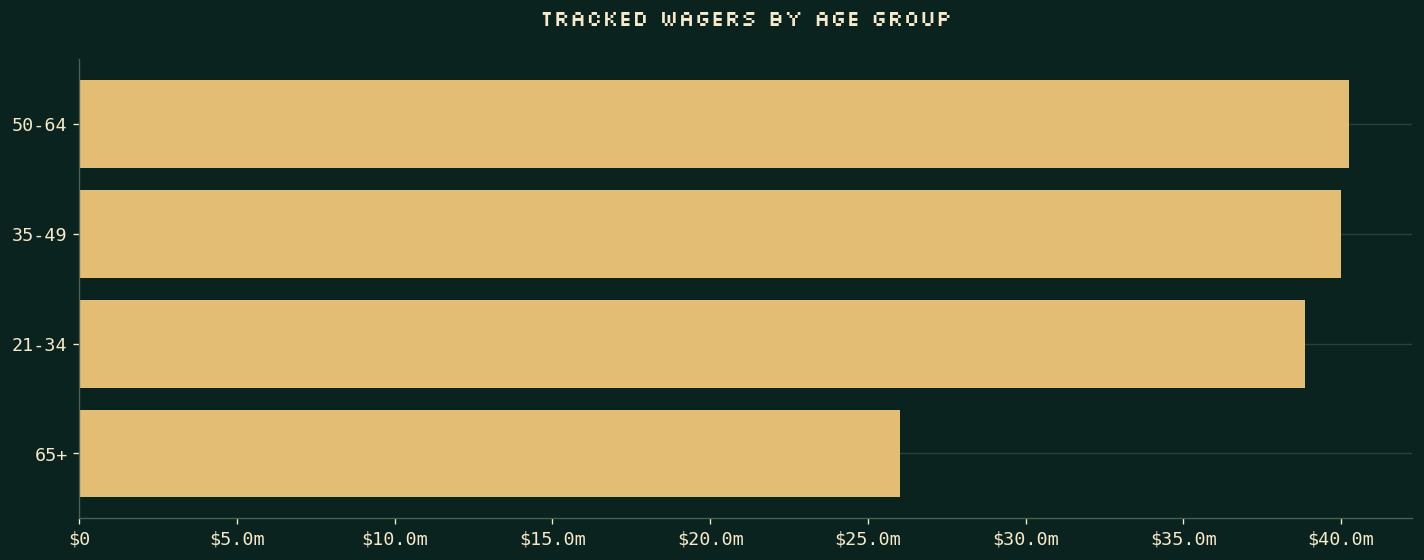

Tracked wagers $163,804,869.65; payouts $148,219,409.05; player net $-15,585,460.60. Carded play is only part of all play.


tracked_players,tracked_wagers,tracked_payouts,player_net,players_ahead_share,top1pct_count,top1pct_wager_share,top1pct_positive_loss_share,tracked_wager_coverage
113890,163804869.65,148219409.05,-15585460.6,0.136131,1139,0.2286,0.198609,0.658101


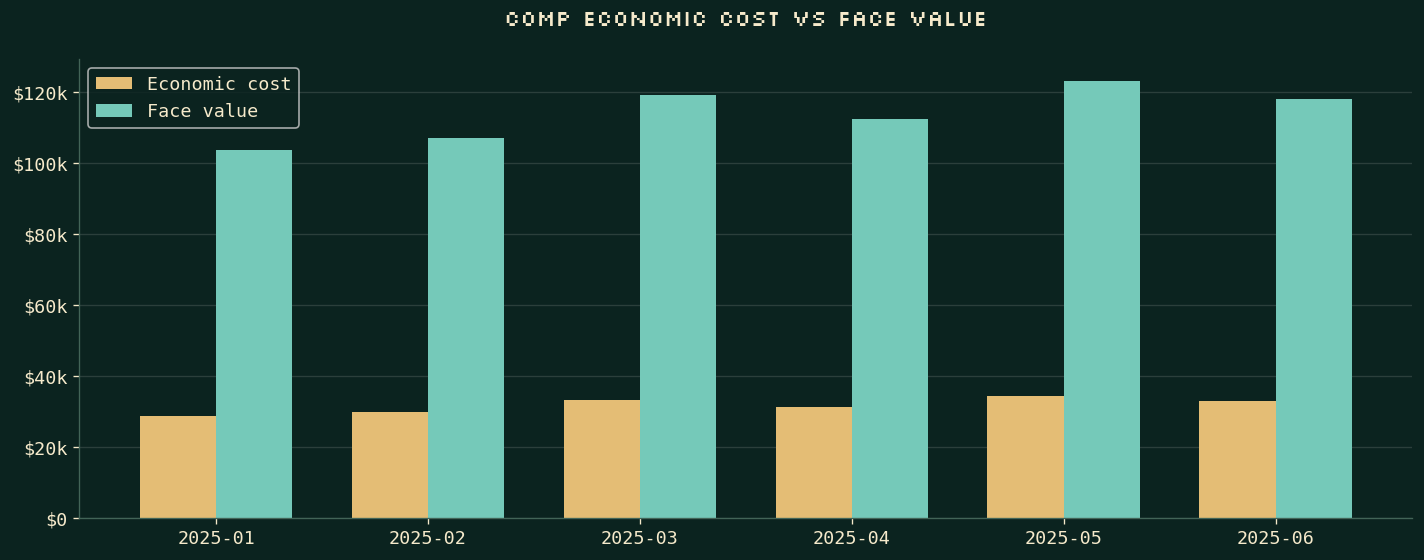

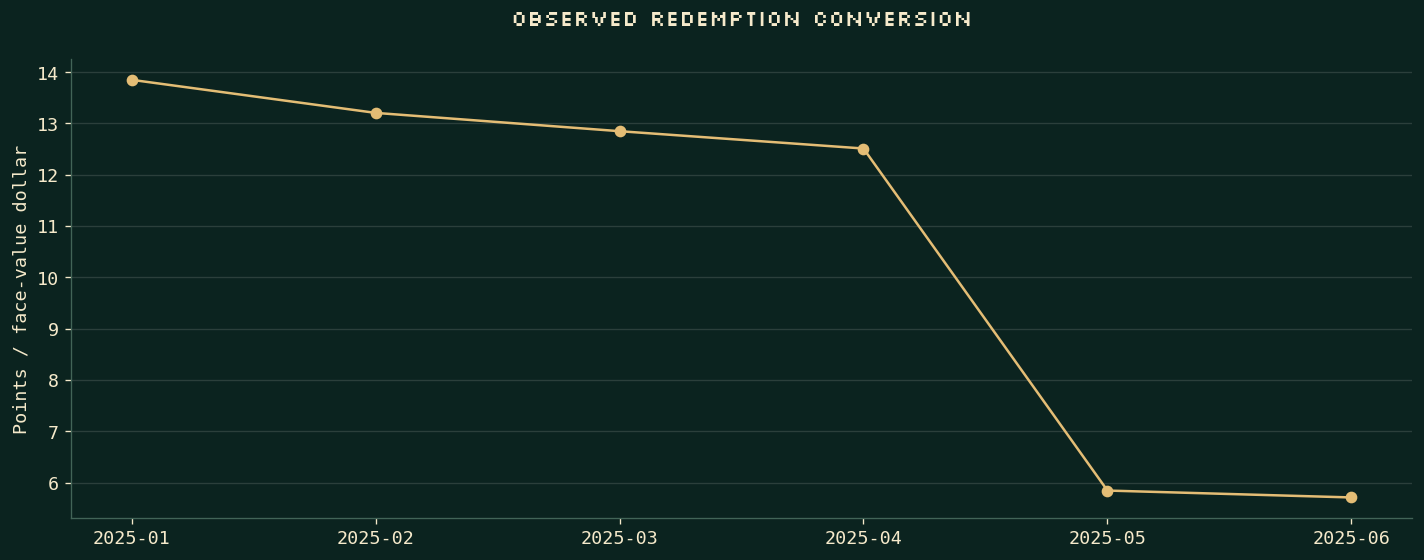

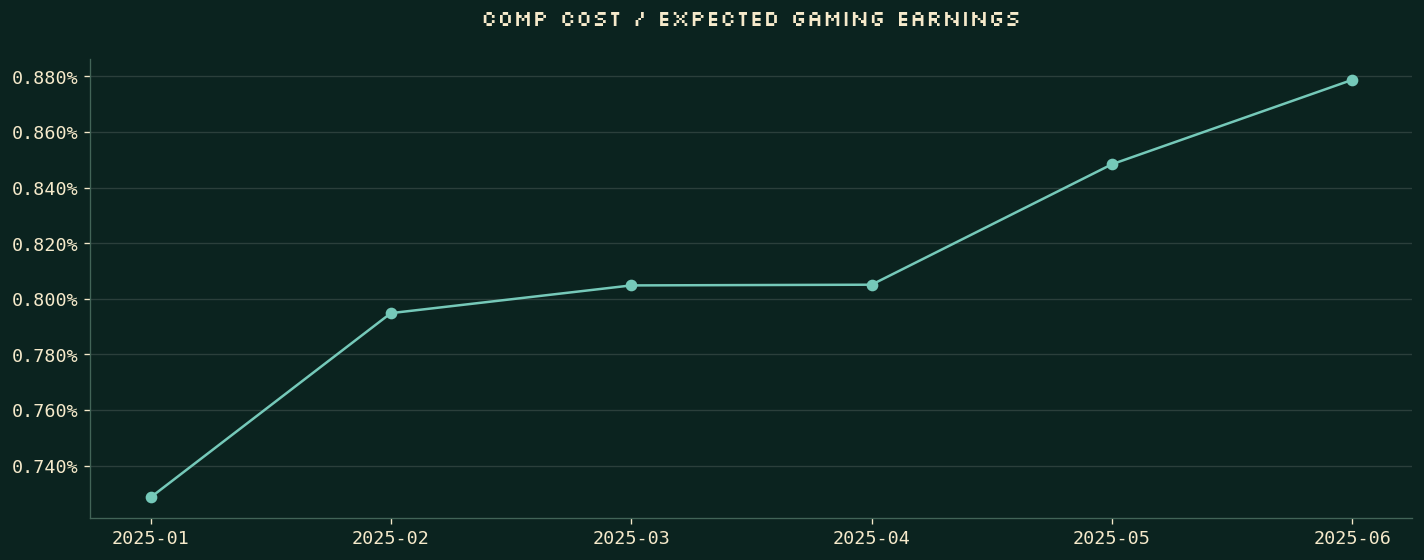

Takeaway: comp economic cost $190,669.30; points per face dollar changed from 13.85 to 5.71. This does not prove a uniform policy change or causal demand effect.


In [8]:
display(fg.groupby('period_month',as_index=False)[['wagers','payouts','player_net','expected','comp_cost','player_months']].sum())
cohort=fg.groupby('age_band',as_index=False).wagers.sum().sort_values('wagers')
fig,ax=figure('Tracked wagers by age group');ax.barh(cohort.age_band,cohort.wagers,color=GOLD);dollars(ax,'x');finish(fig,'10_guest_groups.png')
print(f'Tracked wagers ${fg.wagers.sum():,.2f}; payouts ${fg.payouts.sum():,.2f}; player net ${fg.player_net.sum():,.2f}. Carded play is only part of all play.')
display(pd.DataFrame([fr['players']]))
loyalty=pd.DataFrame(fr['loyalty']);x=np.arange(len(loyalty))
fig,ax=figure('Comp economic cost vs face value');ax.bar(x-.18,loyalty.cost_cents/100,width=.36,color=GOLD,label='Economic cost');ax.bar(x+.18,loyalty.face_cents/100,width=.36,color=TEAL,label='Face value');ax.set_xticks(x,loyalty.gaming_month);ax.legend();dollars(ax);finish(fig,'11_comp_economics.png')
fig,ax=figure('Observed redemption conversion');ax.plot(loyalty.gaming_month,loyalty.points_per_face_dollar,'o-',color=GOLD);ax.set_ylabel('Points / face-value dollar');finish(fig,'12_redemption_conversion.png')
comp=fp.groupby('month',as_index=False).agg(cost=('comp_cost_usd','sum'),theo=('theo_usd','sum'));comp['cost_per_theo']=comp.cost/comp.theo
fig,ax=figure('Comp cost / expected gaming earnings');ax.plot(comp.month,comp.cost_per_theo,'o-',color=TEAL);ax.yaxis.set_major_formatter(ticker.PercentFormatter(1));finish(fig,'13_comp_ratio.png')
print(f'Takeaway: comp economic cost ${loyalty.cost_cents.sum()/100:,.2f}; points per face dollar changed from {loyalty.points_per_face_dollar.iloc[0]:.2f} to {loyalty.points_per_face_dollar.iloc[-1]:.2f}. This does not prove a uniform policy change or causal demand effect.')

## 8. Final forecast: reproduce it, then compare with the archived output
Fit January–March; select constant/weekday using April; refit January–April and freeze the May–June test. Refit January–June only for July. The archived **machine-day MAE improvement is about 16.6%**. The original notebook's **68.5% property-level comparison** is a different historical model and must not be substituted here.

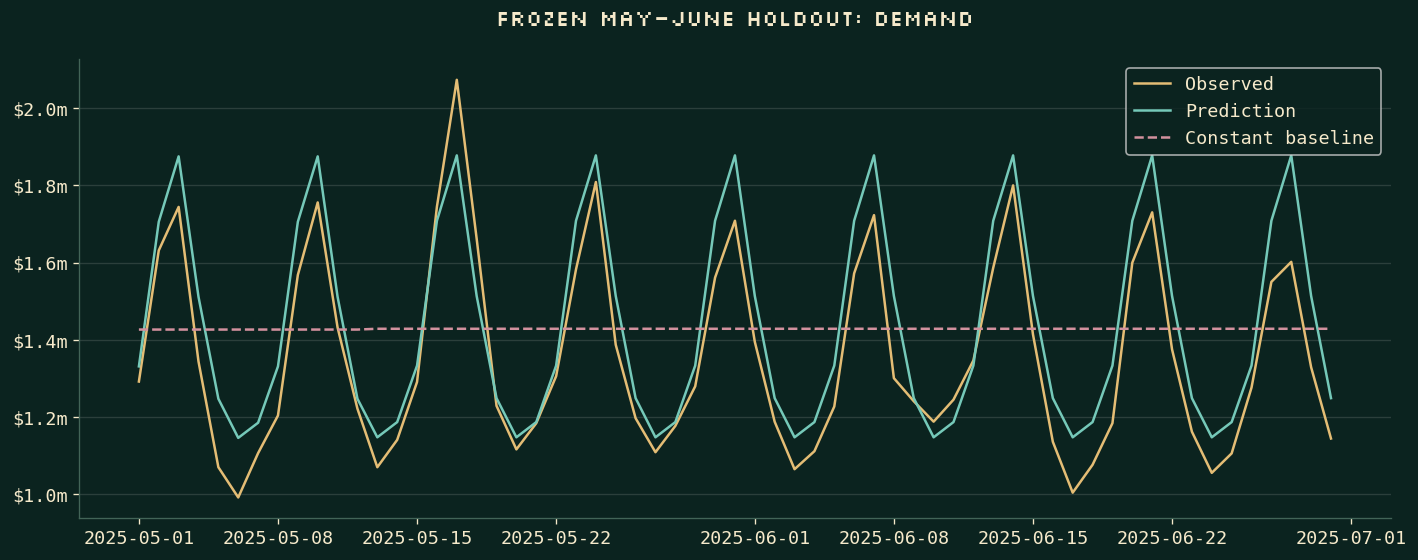

Machine-day MAE $934.98 vs $1,121.28; reduction 16.6%.
Chart lines aggregate machines; MAE above is per machine-day. July actuals are absent. Approximate calibration bands are not guarantees.


model,holdout_mae,baseline_mae,wape
weekday,934.978703,1121.282706,0.212373


In [9]:
rebuilt_predictions, rebuilt_metadata=build_forecasts(fd,fm)
keys=['phase','machine_id','gaming_date']
left=rebuilt_predictions.sort_values(keys).reset_index(drop=True)
right=predictions.sort_values(keys).reset_index(drop=True)
assert left[keys].equals(right[keys])
np.testing.assert_allclose(left.prediction,right.prediction,rtol=1e-10,atol=1e-6)
meta=final_bundle['metadata']
np.testing.assert_allclose(rebuilt_metadata['holdout_mae'],meta['holdout_mae'])
holdout=aggregate_predictions(predictions[predictions.phase=='May–June holdout'],predictions[predictions.phase=='April calibration'])
fig,ax=figure('Frozen May–June holdout: demand')
for col,label,color,ls in [('coin_in_usd','Observed',GOLD,'-'),('prediction','Prediction',TEAL,'-'),('constant','Constant baseline',ROSE,'--')]:ax.plot(holdout.gaming_date,holdout[col],label=label,color=color,ls=ls)
ax.legend();dollars(ax);finish(fig,'14_forecast_holdout.png')
print(f"Machine-day MAE ${meta['holdout_mae']:,.2f} vs ${meta['baseline_mae']:,.2f}; reduction {1-meta['holdout_mae']/meta['baseline_mae']:.1%}.")
print('Chart lines aggregate machines; MAE above is per machine-day. July actuals are absent. Approximate calibration bands are not guarantees.')
display(pd.DataFrame([{'model':meta['model'],'holdout_mae':meta['holdout_mae'],'baseline_mae':meta['baseline_mae'],'wape':meta['holdout_wape']}]))

## 9. The final shared simulation and $100,000 decision
The current dashboard/floor engine uses 1,000 seeded shared draws. Benefits are assumptions, not fitted causal effects. Cash, catalog lead times, recurring costs and planned downtime are explicit. The original nine-target shortlist and the floor's broader individual-action search are different search scopes.

In [10]:
engine=final_bundle['engine']
ranked=rank_portfolios(engine.shortlist(fr['simulation']['candidates'])).sort_values(['Expected net benefit','Cost'],ascending=[False,True])
display(ranked.head(20))
best=ranked.iloc[0]
print('Limited-shortlist recommendation:',best.Actions,'| Mean incremental net:',best['Expected net benefit'])
simulation=FloorSimulation(final_bundle)
empty=simulation.evaluate([])
suggested=simulation.suggestions([])
display(pd.json_normalize(suggested['suggestions']))
print('Search candidates:', suggested['searched'])
print('Suggestions search positive individually feasible moves, lease replacements and manufacturer maintenance against the current plan; not global layout optimization.')
print('Moves use the first legal vacancy. Destination-specific causal lift is unknown. Add/remove and swaps are outside the suggestion search.')

Actions,Cost,Expected net benefit,10th percentile,90th percentile,Chance positive,Stress case
Keep budget,0.0,0.000000,0.000000,0.000000,0.000,0.000000
comp_policy,1500.0,-1164.163738,-4102.835276,1593.189459,0.315,-8665.794046
inspect_M-1181,1200.0,-1215.006473,-1215.006473,-1215.006473,0.000,-1215.006473
inspect_M-1158,1200.0,-1223.945243,-1223.945243,-1223.945243,0.000,-1223.945243
move_weak,1800.0,-1260.234639,-1730.366053,-755.848736,0.003,-2246.254354
signage,7500.0,-2141.633850,-5496.413478,1976.653379,0.228,-7500.000000
inspect_M-1181 + comp_policy,2700.0,-2379.170212,-5317.841749,378.182986,0.135,-9880.800520
inspect_M-1158 + comp_policy,2700.0,-2388.108981,-5326.780518,369.244217,0.134,-9889.739289
inspect_M-1158 + inspect_M-1181,2400.0,-2438.951716,-2438.951716,-2438.951716,0.000,-2438.951716
inspect_M-1181 + move_weak,3000.0,-2475.241113,-2945.372526,-1970.855210,0.000,-3461.260827


Limited-shortlist recommendation: Keep budget | Mean incremental net: 0.0


cost,day,affected,action.id,action.kind,action.target,action.destination,action.retained,marginal.mean,marginal.p10,marginal.p90,marginal.probability_positive
1800.0,3,1,suggest-move-M-2642,move,M-2642,L-07-3,0.5,714.262481,-1475.415920,3063.484179,0.625
1800.0,3,1,suggest-move-M-1114,move,M-1114,L-07-3,0.5,681.798337,-1479.949808,3001.054739,0.616
1800.0,3,1,suggest-move-M-7943,move,M-7943,L-07-3,0.5,675.016457,-1480.622922,2987.718998,0.614


Search candidates: 619
Suggestions search positive individually feasible moves, lease replacements and manufacturer maintenance against the current plan; not global layout optimization.
Moves use the first legal vacancy. Destination-specific causal lift is unknown. Add/remove and swaps are outside the suggestion search.


## 10. Reproduce an atomic swap and July playback
This example is a demonstration, not a selected recommendation. It preserves machine IDs, supplied configurations and roster size. Both moves activate July 3; the swap uses two catalog move units and $3,600 cash. Preview is stateless, confirmation is bound to the plan/action, and undo restores both original positions.

day,date,baseline,expected_gaming_earnings,cash_paid,daily_cash,downtime_opportunity,mean,p10,p90,probability_positive,machine_count
1,2025-07-01,1.060612e+05,1.060612e+05,3600.0,3600.0,0.000000,-3600.000000,-3600.000000,-3600.000000,0.000,308
2,2025-07-02,2.166857e+05,2.166857e+05,3600.0,0.0,0.000000,-3600.000000,-3600.000000,-3600.000000,0.000,308
3,2025-07-03,3.402519e+05,3.402547e+05,3600.0,0.0,138.406963,-3597.264290,-3715.980833,-3469.897879,0.000,308
4,2025-07-04,4.980373e+05,4.982091e+05,3600.0,0.0,138.406963,-3428.149430,-3689.110208,-3148.174652,0.000,308
5,2025-07-05,6.720433e+05,6.723926e+05,3600.0,0.0,138.406963,-3250.744153,-3660.922320,-2810.679781,0.000,308
6,2025-07-06,8.112719e+05,8.117721e+05,3600.0,0.0,138.406963,-3099.868938,-3636.949789,-2523.655560,0.000,308
7,2025-07-07,9.266158e+05,9.272412e+05,3600.0,0.0,138.406963,-2974.612706,-3617.047852,-2285.368759,0.000,308
8,2025-07-08,1.032677e+06,1.033418e+06,3600.0,0.0,138.406963,-2858.980609,-3598.675092,-2065.390862,0.000,308
9,2025-07-09,1.143301e+06,1.144166e+06,3600.0,0.0,138.406963,-2735.848415,-3579.110643,-1831.144819,0.001,308
10,2025-07-10,1.266868e+06,1.267873e+06,3600.0,0.0,138.406963,-2594.705742,-3556.684513,-1562.635735,0.003,308


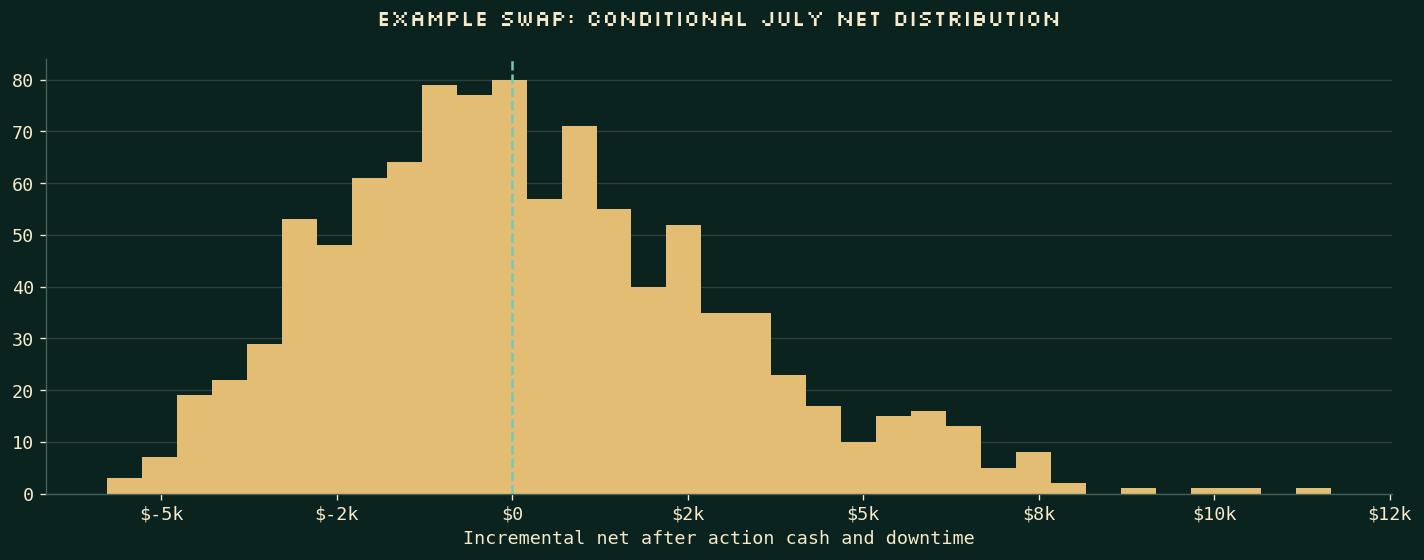

Example swap marginal result: {'mean': 271.82722766086, 'p10': -3101.221685321781, 'p90': 3890.6416134708493, 'probability_positive': 0.49}
Initial machines: 308 | Empty slots: 6 | Swap cash: 3600.0
Added machines use proxy performance × triangular(0.5,1,1.5) × entered incremental share; removals retain only the entered share elsewhere. No resale or operating savings are invented.


In [11]:
targets=sorted(simulation.eligible)[:2]
swap={'id':'notebook-swap','kind':'swap','target':targets[0],'other':targets[1]}
preview=simulation.preview([],swap)
confirmed=simulation.confirm([],swap,preview['estimate_id'])
assert len(simulation.initial)==308
assert all(day['machine_count']==308 for day in confirmed['days'])
assert simulation.undo(confirmed['plan'],swap['id'])['summary']['layout']==simulation.initial
display(pd.DataFrame([{k:v for k,v in day.items() if k not in ['layout','activated']} for day in confirmed['days']]))
fig,ax=figure('Example swap: conditional July net distribution');ax.hist(confirmed['_net'],bins=35,color=GOLD);ax.axvline(0,color=TEAL,ls='--');ax.set_xlabel('Incremental net after action cash and downtime');dollars(ax,'x');finish(fig,'15_swap_distribution.png')
print('Example swap marginal result:',preview['marginal'])
print('Initial machines:',len(simulation.initial),'| Empty slots:',len(simulation.slots)-len(simulation.initial),'| Swap cash:',confirmed['cash_committed'])
print('Added machines use proxy performance × triangular(0.5,1,1.5) × entered incremental share; removals retain only the entered share elsewhere. No resale or operating savings are invented.')

## 11. Final interface and methods
The source archive includes the five-destination application, original pixel font, readable charts, concise takeaways, the optional Evidence Claw, final floor assets, README, Claims & Evidence, AI disclosure and 363-word Devpost draft.

- **Overview:** earnings, normalized demand, ranking choices, residual/event/traffic/downtime evidence and the optional claw.
- **Machines:** actual/expected, monthly availability, same-theme peers and placement history.
- **Guests:** tracked outcomes, concentration, comp costs, redemption conversion and comp-cost ratios.
- **Scenarios:** constrained shortlist, shared uncertainty, frozen forecast evidence and measurement plan.
- **Floor lab:** separate interactive SVG app with drag/drop, atomic swap, previews, suggestions, July playback and undo.

Walking guests are decorative. The claw only selects a raw-bottom-ten investigation candidate; it does not change a model or recommendation. The browser UI is launched locally with `python run_local.py`; Databricks does not host those two localhost services. No Gemini integration exists. Public hosting remains separate.

For intervention evaluation: preregister target, dates, costs and controls; compare availability and contribution per scheduled hour with unchanged peers; monitor whole-floor play for displacement. Conditional planning estimates do not establish an action's real-world benefit.

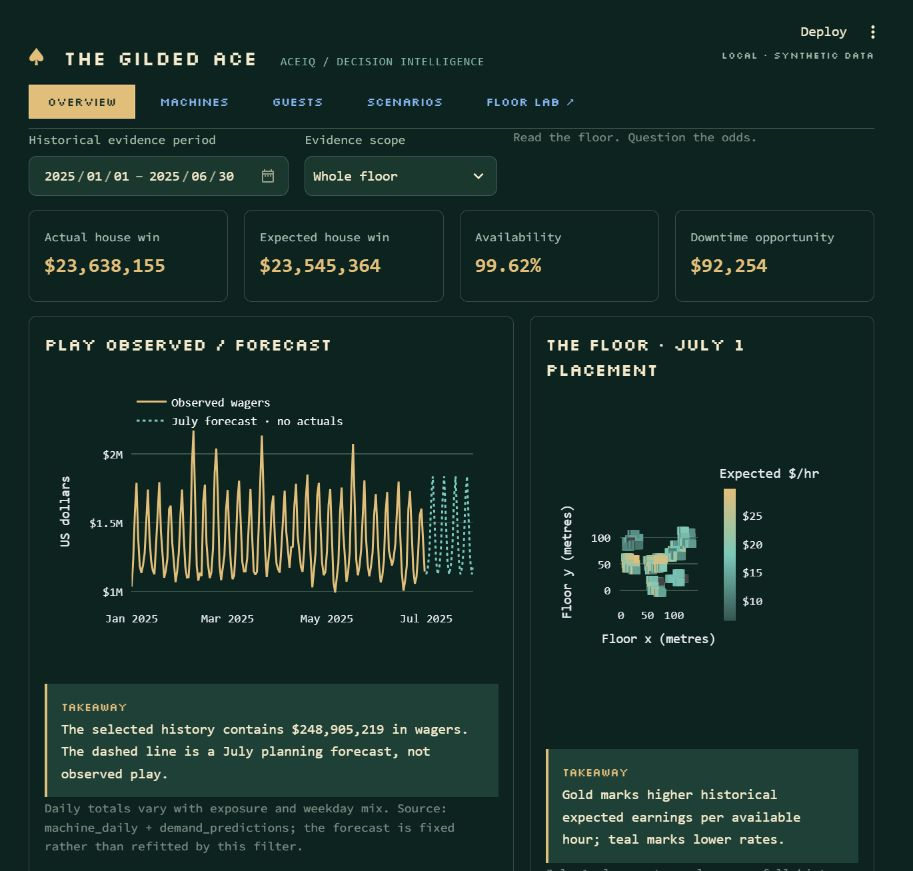

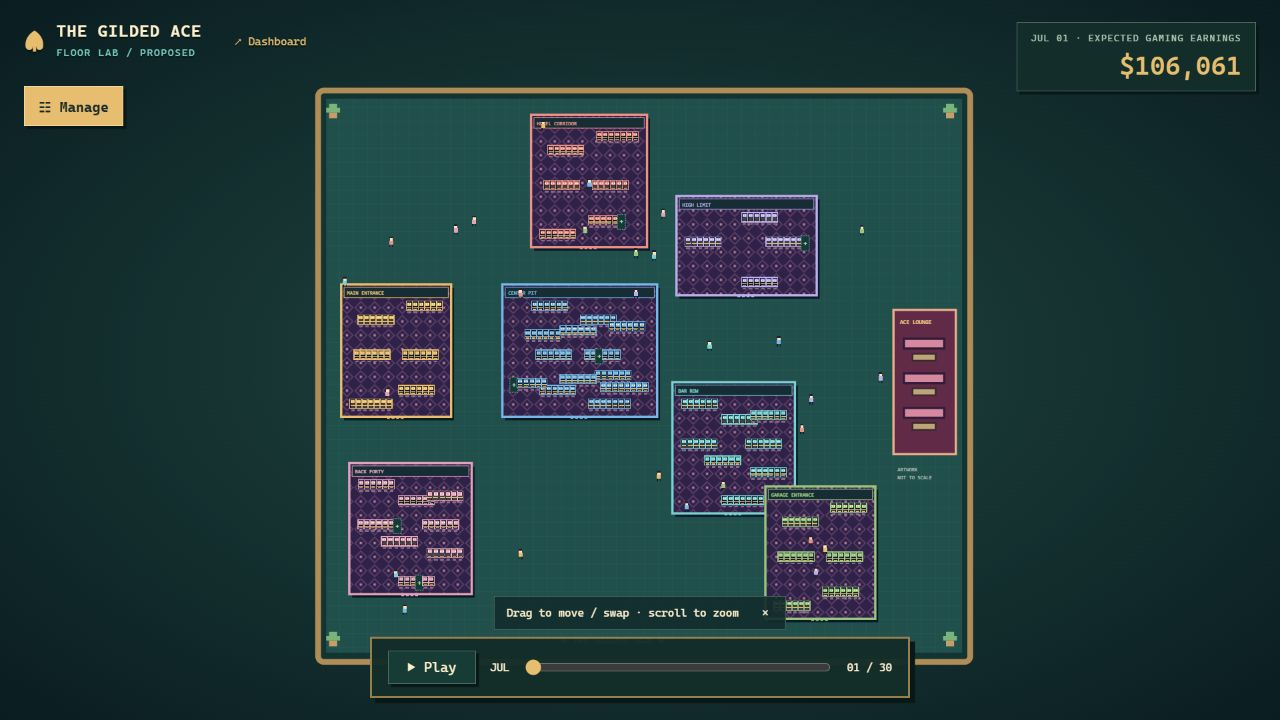

# Final comparison with Datathon Project Ideation.pdf

Reviewed November 8, 2026. The supplied 147-page PDF contains earlier application source code, not the underlying Parquet/JSON datasets or a set of rendered chart outputs. We can verify shared data definitions and reconcile the current local exports; we cannot claim the PDF embeds an identical dataset.

The current interface is **not a pixel-for-pixel or model-for-model copy**. It preserves the core historical calculations, improves chart readability and labels newer modeling separately. No original data export, notebook or shared model was changed in this presentation update.

## Chart and calculation mapping

| PDF evidence | Current interface | Comparison |
|---|---|---|
| Bottom ten by total actual, actual/day or expected/hour; actual/expected index (pp. 70–73) | Overview ranking selector and 100% reference bar chart | Same definitions; negative ratios are retained instead of being clipped. |
| Residual uncertainty scatter (pp. 73–75) | Overview expandable payout-variation screen | Same dollar residual and selected-period modeled standard deviation definitions. Not a corrected hypothesis test. |
| Evidence Claw (pp. 75–79) | Optional Overview claw | Randomly surfaces one of the raw bottom ten; no change to rankings or recommendation. New lightweight animation, not the original component. |
| Monthly wagers per available machine-hour (pp. 79–81) | Overview demand-rate chart | Daily machine rollups reconcile to property wagers and available hours. Current zone filter can narrow the cohort; the PDF property chart was property-wide. |
| Cumulative actual/expected, availability and peers | Machines | Same historical measures. Monthly unavailable hours are charted; exact availability is retained in the table. Peer scatter adds availability to the expected/hour comparison rather than copying the old peer bar chart. |
| Placement and observed move comparisons (pp. 93–95) | Machine placement table and July 1 floor | Placement history is available; the older descriptive before/after peer-adjusted movement comparison is not reproduced. July floor actions are hypothetical. |
| Event differences versus weekday baseline (pp. 120–121) | Overview event-context expansion | Same report rows; fractional differences multiplied by 100 for percentage display. Fixed full-property context, not current date/zone filters. |
| Traffic per covered hour (p. 122) | Overview traffic-context expansion | Same report rows and covered-hour denominator. Coverage shown; entries are not unique visitors. |
| Guest group wagers (pp. 125–129) | Guests age-band chart and region filter | Same grouped exports. Guest months are whole included months; no individual identifiers or new unique-player counts inferred. |
| Comp cost and face value (pp. 130–131) | Guests grouped bars | Same cent-to-dollar conversion. Uses one common dollar axis instead of the PDF's dual-axis bar/line display. |
| Points per face dollar and comp cost/theo (pp. 132–133) | Guests loyalty-change expansion | Same formulas. Redemption rows cover complete included months; daily property ratio follows exact selected dates. Never subtract linked comp cost and POS COGS twice. |
| Downtime opportunity by zone (p. 138) | Overview downtime expansion | Same missed-theo estimates summed by selected zone/date records. Opportunity is not proven net floor loss. |
| Forecast comparisons (pp. 116–124) | Scenarios frozen holdout, prediction and constant baseline | Current machine-level model and its MAE are separate from the historical property-level model; see below. |
| Original saved simulation and manual action sandbox | Scenarios shared engine; standalone Floor lab | Original simulation remains downloadable/inspectable historical evidence. Current results use the shared seeded engine and are not asserted equal to the PDF's separate sandbox estimates. |

## Reconciled evidence

- Historical wagers: **$248,905,219.25**.
- Actual house win: **$23,638,155.10**; implied payouts: **$225,267,064.15**.
- Expected house win: **$23,545,364.48**.
- Tracked wagers: **$163,804,869.65**; tracked payouts: **$148,219,409.05**; player net: **−$15,585,460.60**.
- Property economic comp cost: **$190,669.30**, reconciling to redemption cents after conversion.
- Daily property wagers, house win, theo and available machine-hours reconcile to daily machine rollups. Monthly exposure-adjusted demand therefore agrees for the whole floor.
- Current frozen holdout MAE: **$934.98 per machine-day**, versus **$1,121.28** for the constant baseline (about **16.6% lower**). The historical report's **68.5%** improvement concerns a different property-level forecast and is not interchangeable with this score.

## Checks and boundaries

`tests/test_reference_consistency.py` independently verifies money reconciliation, daily/property rollups, monthly exposure, selected-period variance, player net, redemption conversions, event units, traffic coverage denominators, holdout error scores and absent July actuals. The PDF itself is reference material, not executable instructions or permission to change data.

The existing results, upgrade, floor simulation, HTTP boundary, geometry and Streamlit tests remain applicable. The current README describes supported checks; inherited `tests/test_app.py` targets an older interface. No live Databricks/Gemini API was added. Public floor hosting remains separate from this GitHub update.


## Inspiration

The Gilded Ace manager wants to replace the ten slot machines with the lowest earnings. What sounded like a ranking problem became an investigation: low earnings can reflect limited exposure, downtime, demand or unusual payouts.

That became the question behind AceIQ: **is a machine truly underperforming, or is it being judged unfairly?** We wanted to make the evidence understandable before recommending an expensive decision.

## What it does

AceIQ combines a retro Streamlit dashboard with an interactive casino floor. Users compare actual and expected earnings, active days, availability, payout variation and same-theme peers. Date filters update machine evidence, while concise chart summaries explain findings and limitations.

The dashboard covers demand, event associations, traffic coverage, tracked-player outcomes, comp economics and forecast validation. Its July planner compares actions within a $100,000 cash budget using 1,000 seeded Monte Carlo draws.

The floor supports moving, swapping, adding and removing machines, plus inspection, replacement and maintenance scenarios. Users preview costs, uncertainty and incremental net before confirming, play through July, review suggestions and undo changes. Walking guests are decorative; forecasts and assumed action effects drive the financial model.

## How we built it

We used Python, Streamlit, Pandas, NumPy, Plotly and PyArrow, with local synthetic Parquet, JSON and NPZ exports. Databricks notebooks preserve the original analysis; the app runs without a live connection. JavaScript, SVG and CSS power the floor.

We reconciled totals, adjusted comparisons for exposure, incorporated supplied payout variance and documented claims. Forecast selection uses January–March training and April validation, followed by a January–April refit and frozen May–June test against a constant baseline. July remains unobserved.

## Challenges we ran into

We started with little experience in large datasets, theoretical win or operational planning. We learned to distinguish tracked play from total activity, avoid double-counting comp costs, and separate location associations from causal evidence.

Another challenge was keeping scenario assumptions visible instead of presenting simulated returns as guarantees.

## What we learned

A useful dashboard connects questions, evidence and decisions. Validation, understandable comparisons and honest uncertainty matter as much as visual design.

## Built With

Python, Streamlit, Pandas, NumPy, Plotly, PyArrow, Databricks, JavaScript, SVG, CSS, Parquet, JSON, NumPy NPZ, time-series forecasting and Monte Carlo simulation.


In [12]:
from IPython.display import Image, Markdown, display as ipy_display
ipy_display(Image(filename=str(FINAL_ROOT/'docs/dashboard.png')))
ipy_display(Image(filename=str(FINAL_ROOT/'docs/floor-lab.png')))
ipy_display(Markdown((FINAL_ROOT/'docs/REFERENCE_COMPARISON.md').read_text(encoding='utf-8')))
ipy_display(Markdown((FINAL_ROOT/'docs/DEVPOST.md').read_text(encoding='utf-8')))

## 12. Verification record
The successful end of this cell establishes which source snapshot ran. It records cloud/local reconciliation, reproduced forecasts and engine regression checks. UI/HTTP/geometry checks were performed locally and are separately documented; this cell does not claim they ran on Databricks.

In [13]:
verification={'git_commit':source_manifest['git_commit'],'archive_sha256':EXPECTED_SHA256,
 'verified_source_files':len(source_manifest['files']),'cloud_table_reconciled':True,
 'cloud_totals':{k:float(v) for k,v in cloud.items()},'local_totals':local,
 'regression_tests':test_result.testsRun,'regressions_passed':test_result.wasSuccessful(),
 'leakage_and_placement_checks_passed':True,'forecast_reproduced':True,
 'machine_day_mae':meta['holdout_mae'],'baseline_mae':meta['baseline_mae'],
 'shortlist_recommendation':best.Actions,'shortlist_mean_net':float(best['Expected net benefit']),
 'initial_machines':len(simulation.initial),'vacancies':len(simulation.slots)-len(simulation.initial),
 'swap_cash':confirmed['cash_committed'],'swap_preserved_roster':True,'charts':chart_files,
 'verified_at_utc':pd.Timestamp.now(tz='UTC').isoformat()}
(VERIFY/'verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
print(json.dumps(verification,indent=2))
print('FINAL PRODUCT VERIFICATION PASSED')

{
  "git_commit": "2a124ca0b901ab9e4c18d87f471679c0673600a1",
  "archive_sha256": "f8b6e0d01983c1e6a249a0cc2d4c03e9f1a8ca3e3afe0a41de14d101d7d72e99",
  "verified_source_files": 76,
  "cloud_table_reconciled": true,
  "cloud_totals": {
    "active_rows": 55092.0,
    "wagers": 248905219.25,
    "payouts": 225267064.15,
    "actual": 23638155.1,
    "expected": 23545364.4785
  },
  "local_totals": {
    "active_rows": 55092,
    "wagers": 248905219.25,
    "payouts": 225267064.15,
    "actual": 23638155.099999998,
    "expected": 23545364.4785
  },
  "regression_tests": 16,
  "regressions_passed": true,
  "leakage_and_placement_checks_passed": true,
  "forecast_reproduced": true,
  "machine_day_mae": 934.9787031541359,
  "baseline_mae": 1121.2827064709136,
  "shortlist_recommendation": "Keep budget",
  "shortlist_mean_net": 0.0,
  "initial_machines": 308,
  "vacancies": 6,
  "swap_cash": 3600.0,
  "swap_preserved_roster": true,
  "charts": [
    "01_bottom_ten.png",
    "02_residuals.png